# MathTrans — Phase 1 Full Notebook

**Before running:** Runtime → Change runtime type → **T4 GPU**

| Section | What it does |
|---|---|
| 0 | Install & mount Drive |
| 1 | All imports & config |
| 2 | Helper functions — each one shows example output |
| 3 | Model & tokenizer — inspect vocab, LoRA layers |
| 4 | Data pipeline — inspect each stage |
| 5 | Training — auto-resumes from checkpoint |
| 6 | Checkpoint explorer — test any of 6 checkpoints vs base model |
| 7 | Full metrics plots — loss, chrF++, BLEU, LR, bar chart |
| 8 | arXiv / PDF translator interface |

## Section 0 — Install & mount Drive

In [1]:
# 0.1 Install
!pip install -q transformers==4.40.2 peft==0.10.0 datasets accelerate==0.30.1 evaluate sacrebleu sentencepiece pymupdf4llm matplotlib requests beautifulsoup4
print("✓ packages installed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.0/138.0 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 95.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.1/199.1 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.6/302.6 kB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.3/77.3 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 109.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 46.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 131.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 108.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not curr

In [2]:
# 0.2 Mount Drive & set paths
from google.colab import drive
drive.mount('/content/drive')
import os, torch

DRIVE_ROOT  = '/content/drive/MyDrive/mathtrans'
DATA_PATH   = f'{DRIVE_ROOT}/phase1.jsonl'
CKPT_DIR    = f'{DRIVE_ROOT}/checkpoints'
SEEN_PATH   = f'{DRIVE_ROOT}/seen_hashes.txt'
CURVES_PATH = f'{CKPT_DIR}/training_curves.json'
os.makedirs(CKPT_DIR, exist_ok=True)

print(f"GPU : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE — go to Runtime → Change runtime type'}")
if torch.cuda.is_available():
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
print(f"Data file exists: {os.path.exists(DATA_PATH)}")

Mounted at /content/drive
GPU : Tesla T4
VRAM: 15.6 GB
Data file exists: True


## Section 1 — Imports & config

In [3]:
# 1.1 All imports
import os, re, json, math, hashlib, logging, warnings
from pathlib import Path
from IPython.display import display, HTML

os.environ.setdefault('PYTORCH_ALLOC_CONF', 'expandable_segments:True')
warnings.filterwarnings('ignore')

import torch, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from datasets import Dataset, DatasetDict
from transformers import (
    NllbTokenizerFast, AutoModelForSeq2SeqLM,
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq, EarlyStoppingCallback, TrainerCallback,
)
from peft import LoraConfig, TaskType, get_peft_model
import evaluate as hf_evaluate

device = 'cuda' if torch.cuda.is_available() else 'cpu'
logging.basicConfig(level=logging.INFO, format='%(asctime)s | %(levelname)s | %(message)s')
log = logging.getLogger(__name__)
print("✓ All imports OK  |  device:", device)

✓ All imports OK  |  device: cuda


In [4]:
# 1.2 Config — edit values here, everything else reads from these dicts
MODEL_NAME = 'facebook/nllb-200-1.3B'
LANG_CODE  = {'en': 'eng_Latn', 'ar': 'arb_Arab'}

LORA_CONFIG = dict(
    r=16, lora_alpha=32,
    target_modules=['q_proj','k_proj','v_proj','out_proj'],
    lora_dropout=0.05, bias='none',
    task_type=TaskType.SEQ_2_SEQ_LM,
)

TRAIN_CONFIG = dict(
    max_source_length=256, max_target_length=256,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=16,    # effective batch = 64
    learning_rate=3e-4,
    lr_scheduler_type='cosine',
    warmup_ratio=0.06,
    num_train_epochs=3,
    weight_decay=0.01,
    label_smoothing_factor=0.0,       # must be 0.0 with PEFT
    val_split=0.05,
    logging_steps=50,
    eval_steps=200,
    save_steps=200,
    save_total_limit=5,
    eval_num_beams=1,                 # greedy eval = no OOM
    eval_generation_max_length=128,
    final_num_beams=4,
    final_generation_max_length=256,
    seed=42,
)

for k,v in TRAIN_CONFIG.items():
    print(f"  {k:<35} = {v}")

  max_source_length                   = 256
  max_target_length                   = 256
  per_device_train_batch_size         = 4
  per_device_eval_batch_size          = 4
  gradient_accumulation_steps         = 16
  learning_rate                       = 0.0003
  lr_scheduler_type                   = cosine
  warmup_ratio                        = 0.06
  num_train_epochs                    = 3
  weight_decay                        = 0.01
  label_smoothing_factor              = 0.0
  val_split                           = 0.05
  logging_steps                       = 50
  eval_steps                          = 200
  save_steps                          = 200
  save_total_limit                    = 5
  eval_num_beams                      = 1
  eval_generation_max_length          = 128
  final_num_beams                     = 4
  final_generation_max_length         = 256
  seed                                = 42






## Section 2 — Helper functions

Run each cell to define the function. The inspection block at the bottom of each cell shows real output.

In [5]:
# 2.1 Sentence splitter  +  inspection
_SENT_SPLIT = re.compile(r'(?<=[.!?\u061F])\s+(?=[A-Z\u0600-\u06FF"])')
_ABBREV = re.compile(
    r'\b(Thm|Lem|Prop|Cor|Def|Eq|Fig|Sec|Ch|Vol|et al|e\.g|i\.e|vs|cf|resp|approx)\.\s',
    re.IGNORECASE,
)

def split_sentences(text):
    protected = _ABBREV.sub(lambda m: m.group().replace('. ', '\x00 '), text)
    parts = _SENT_SPLIT.split(protected)
    return [p.replace('\x00','.').strip() for p in parts if p.strip()]

def split_pair(src, tgt):
    direction, clean_src = '', src
    if src.startswith('<en2ar>'): direction, clean_src = '<en2ar>', src[7:].strip()
    elif src.startswith('<ar2en>'): direction, clean_src = '<ar2en>', src[7:].strip()
    src_sents = split_sentences(clean_src)
    tgt_sents = split_sentences(tgt)
    if len(src_sents)==len(tgt_sents) and len(src_sents)>1:
        pairs=[]
        for s,t in zip(src_sents,tgt_sents):
            if len(s)>=10 and len(t)>=10:
                tag=f'{direction} ' if direction else ''
                pairs.append((f'{tag}{s}',t))
        return pairs if pairs else [(src,tgt)]
    return [(src,tgt)]

# ── inspection ──
EXAMPLE_SRC = '<en2ar> Let f be a measurable function. We say f is integrable if the Lebesgue integral of |f| is finite. This condition is equivalent to f being in L^1.'
EXAMPLE_TGT = 'لتكن f دالة قابلة للقياس. نقول إن f قابلة للتكامل إذا كان تكامل لوبيغ لـ|f| منتهياً. هذا الشرط يعادل كون f في L^1.'
pairs = split_pair(EXAMPLE_SRC, EXAMPLE_TGT)
print(f"1 abstract → {len(pairs)} sentence pairs:")
for i,(s,t) in enumerate(pairs):
    print(f"  [{i}] EN: {s}")
    print(f"       AR: {t}")

1 abstract → 3 sentence pairs:
  [0] EN: <en2ar> Let f be a measurable function.
       AR: لتكن f دالة قابلة للقياس.
  [1] EN: <en2ar> We say f is integrable if the Lebesgue integral of |f| is finite.
       AR: نقول إن f قابلة للتكامل إذا كان تكامل لوبيغ لـ|f| منتهياً.
  [2] EN: <en2ar> This condition is equivalent to f being in L^1.
       AR: هذا الشرط يعادل كون f في L^1.


In [6]:
# 2.2 Seen-hash tracking  +  inspection
def pair_hash(src):
    clean = re.sub(r'^<(en2ar|ar2en)>\s*','',src).lower()[:120]
    return hashlib.md5(clean.encode()).hexdigest()

def load_seen_hashes(path):
    p=Path(path)
    return set(p.read_text().splitlines()) if p.exists() else set()

def save_new_hashes(path, hashes):
    with open(path,'a',encoding='utf-8') as f:
        for h in hashes: f.write(h+'\n')
    print(f"  Saved {len(hashes)} hashes → {path}")

# ── inspection ──
h1=pair_hash('<en2ar> The function f is continuous.')
h2=pair_hash('<en2ar> The function f is continuous.')
h3=pair_hash('<ar2en> الدالة f مستمرة.')
print(f"Same sentence twice     : {h1==h2}  (identical hash = dedup works)")
print(f"Different sentence      : {h1!=h3}  (different hash = not deduped)")
print(f"Hash example            : {h1}")

Same sentence twice     : True  (identical hash = dedup works)
Different sentence      : True  (different hash = not deduped)
Hash example            : 73695a74ff7f8468d9bdbc62e7ecb2cc


In [7]:
# 2.3 Data loading  +  inspection
def load_data(data_paths, seen_hashes, val_split=0.05, seed=42, retrain_all=False):
    records,new_hashes,dedup=[],[],set()
    n_seen=n_invalid=n_split=0
    for path in data_paths:
        with open(path,encoding='utf-8') as f:
            for line in f:
                line=line.strip()
                if not line: continue
                try: obj=json.loads(line)
                except: n_invalid+=1; continue
                src=obj.get('source','').strip()
                tgt=obj.get('target','').strip()
                if not src or not tgt or len(src)<10 or len(tgt)<10:
                    n_invalid+=1; continue
                h=pair_hash(src)
                if not retrain_all and h in seen_hashes: n_seen+=1; continue
                if h in dedup: continue
                dedup.add(h)
                pairs=split_pair(src,tgt)
                if len(pairs)>1: n_split+=1
                for s,t in pairs:
                    if len(s)>=10 and len(t)>=10 and s!=t:
                        records.append({'source':s,'target':t})
                new_hashes.append(h)
    print(f"  Sentence pairs loaded : {len(records)}")
    print(f"  Raw pairs             : {len(new_hashes)}")
    print(f"  Multi-sent expanded   : {n_split}")
    print(f"  Skipped seen          : {n_seen}  |  invalid: {n_invalid}")
    ds=Dataset.from_list(records)
    split=ds.train_test_split(test_size=val_split,seed=seed)
    return DatasetDict({'train':split['train'],'validation':split['test']}),new_hashes

# ── inspection ──
if os.path.exists(DATA_PATH):
    seen=load_seen_hashes(SEEN_PATH)
    print(f"Seen hashes: {len(seen)}")
    datasets,new_hashes=load_data([DATA_PATH],seen)
    src_lens=[len(r['source'].split()) for r in datasets['train']]
    tgt_lens=[len(r['target'].split()) for r in datasets['train']]
    en2ar=sum(1 for r in datasets['train'] if r['source'].startswith('<en2ar>'))
    ar2en=len(datasets['train'])-en2ar
    print(f"  Train/Val split : {len(datasets['train'])} / {len(datasets['validation'])}")
    print(f"  EN→AR / AR→EN   : {en2ar} / {ar2en}  ({100*en2ar/(en2ar+ar2en):.0f}% / {100*ar2en/(en2ar+ar2en):.0f}%)")
    print(f"  Src words avg/p95: {np.mean(src_lens):.1f} / {np.percentile(src_lens,95):.0f}")
    print(f"  Tgt words avg/p95: {np.mean(tgt_lens):.1f} / {np.percentile(tgt_lens,95):.0f}")
else:
    print(f"Data not found at {DATA_PATH} — upload your JSONL first")

Seen hashes: 0
  Sentence pairs loaded : 79670
  Raw pairs             : 78550
  Multi-sent expanded   : 581
  Skipped seen          : 0  |  invalid: 0
  Train/Val split : 75686 / 3984
  EN→AR / AR→EN   : 37871 / 37815  (50% / 50%)
  Src words avg/p95: 23.7 / 41
  Tgt words avg/p95: 22.7 / 40


In [8]:
# 2.4 Tokenisation function  (instantiated after tokenizer loads in S3)
def make_tokenize_fn(tokenizer, max_src, max_tgt):
    def tokenize(batch):
        ii,am,lb=[],[],[]
        for src,tgt in zip(batch['source'],batch['target']):
            if src.startswith('<en2ar>'):
                tokenizer.src_lang=LANG_CODE['en']; tokenizer.tgt_lang=LANG_CODE['ar']
                clean=src[7:].strip()
            elif src.startswith('<ar2en>'):
                tokenizer.src_lang=LANG_CODE['ar']; tokenizer.tgt_lang=LANG_CODE['en']
                clean=src[7:].strip()
            else:
                has_ar=any('\u0600'<=c<='\u06FF' for c in src)
                tokenizer.src_lang=LANG_CODE['ar' if has_ar else 'en']
                tokenizer.tgt_lang=LANG_CODE['en' if has_ar else 'ar']
                clean=src
            enc=tokenizer(clean,max_length=max_src,truncation=True,padding=False)
            dec=tokenizer(text_target=tgt,max_length=max_tgt,truncation=True,padding=False)
            labels=[l if l!=tokenizer.pad_token_id else -100 for l in dec['input_ids']]
            ii.append(enc['input_ids']); am.append(enc['attention_mask']); lb.append(labels)
        return {'input_ids':ii,'attention_mask':am,'labels':lb}
    return tokenize
print("make_tokenize_fn defined — will be used after tokenizer loads")

make_tokenize_fn defined — will be used after tokenizer loads


In [9]:
# 2.5 Metrics  +  inspection
def build_compute_metrics(tokenizer):
    chrf=hf_evaluate.load('chrf')
    bleu=hf_evaluate.load('sacrebleu')
    def compute_metrics(eval_preds):
        preds,labels=eval_preds
        if isinstance(preds,tuple): preds=preds[0]
        preds =np.where(preds !=-100,preds, tokenizer.pad_token_id)
        labels=np.where(labels!=-100,labels,tokenizer.pad_token_id)
        dp=[p.strip() for p in tokenizer.batch_decode(preds, skip_special_tokens=True)]
        dl=[l.strip() for l in tokenizer.batch_decode(labels,skip_special_tokens=True)]
        c=chrf.compute(predictions=dp,references=dl,word_order=2)
        b=bleu.compute(predictions=dp,references=[[l] for l in dl])
        return {'chrf':round(c['score'],2),'bleu':round(b['score'],2)}
    return compute_metrics

# ── inspection: what do these numbers mean? ──
chrf_m=hf_evaluate.load('chrf')
bleu_m=hf_evaluate.load('sacrebleu')
ref  = 'يُعرَّف تكامل لوبيغ لدالة قابلة للقياس غير سالبة بوصفه الحد الأعلى لتكاملات الدوال البسيطة'
good = 'يُعرَّف تكامل لوبيغ لدالة قابلة للقياس غير سالبة بوصفه الحد الأعلى'
bad  = 'هذه الجملة خاطئة تماما ولا علاقة لها بالنص الأصلي'
for label,pred in [('Good (partial match)',good),('Bad (wrong content)',bad)]:
    c=chrf_m.compute(predictions=[pred],references=[ref],word_order=2)
    b=bleu_m.compute(predictions=[pred],references=[[ref]])
    print(f"{label}:")
    print(f"  chrF++ = {c['score']:.1f}   BLEU = {b['score']:.1f}")

Good (partial match):
  chrF++ = 77.4   BLEU = 76.1
Bad (wrong content):
  chrF++ = 8.5   BLEU = 0.0


In [10]:
# 2.6 Callbacks & checkpoint utils  +  inspection
class ClearCacheBeforeEval(TrainerCallback):
    def on_evaluate(self,args,state,control,**kw):
        if torch.cuda.is_available(): torch.cuda.empty_cache()

class SaveCurvesCallback(TrainerCallback):
    def __init__(self,path): self.path=path
    def on_evaluate(self,args,state,control,**kw):
        with open(self.path,'w') as f: json.dump(state.log_history,f,indent=2)

def find_checkpoints(output_dir):
    d=Path(output_dir)
    if not d.exists(): return []
    ckpts=sorted(d.glob('checkpoint-*'),key=lambda p:int(p.name.split('-')[-1]))
    return ckpts

def find_latest_checkpoint(output_dir):
    ckpts=find_checkpoints(output_dir)
    if not ckpts: return None,0
    latest=ckpts[-1]
    return str(latest),int(latest.name.split('-')[-1])

# ── inspection: list checkpoints ──
ckpts=find_checkpoints(CKPT_DIR)
if ckpts:
    print(f"Found {len(ckpts)} checkpoint(s):")
    for c in ckpts:
        size_mb=sum(f.stat().st_size for f in c.iterdir() if f.is_file())/1e6
        print(f"  {c.name:<25}  {size_mb:.0f} MB")
else:
    print("No checkpoints yet — they appear here after training starts (every 200 steps)")

Found 8 checkpoint(s):
  checkpoint-600             136 MB
  checkpoint-1000            136 MB
  checkpoint-2000            136 MB
  checkpoint-2600            136 MB
  checkpoint-2800            136 MB
  checkpoint-3000            136 MB
  checkpoint-3200            136 MB
  checkpoint-3400            136 MB


## Section 3 — Model & tokenizer setup

In [11]:
# 3.1 Load tokenizer
print(f"Loading tokenizer: {MODEL_NAME}")
tokenizer=NllbTokenizerFast.from_pretrained(MODEL_NAME)
n_added=tokenizer.add_special_tokens({'additional_special_tokens':['<en2ar>','<ar2en>']})
print(f"Vocab size : {len(tokenizer)}")
print(f"Tokens added: {n_added}  (<en2ar>, <ar2en>)")

# ── inspection: see how NLLB tokenises a math sentence ──
tokenizer.src_lang='eng_Latn'
tok_out=tokenizer('The Lebesgue integral converges almost everywhere.',return_tensors='pt')
tokens=tokenizer.convert_ids_to_tokens(tok_out['input_ids'][0].tolist())
print(f"\nExample tokenisation:")
print(f"  Tokens : {tokens}")
print(f"  Count  : {tok_out['input_ids'].shape[1]} tokens  (direction token adds 1)")

Loading tokenizer: facebook/nllb-200-1.3B


tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/4.85M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.3M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Vocab size : 256206
Tokens added: 2  (<en2ar>, <ar2en>)

Example tokenisation:
  Tokens : ['eng_Latn', '▁The', '▁Leb', 'es', 'gue', '▁integral', '▁conver', 'ges', '▁almost', '▁everywhere', '.', '</s>']
  Count  : 12 tokens  (direction token adds 1)


In [12]:
# 3.2 Load model & apply LoRA (downloads ~2.6 GB on first run)
print(f"Loading {MODEL_NAME} ...")
model=AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if device=='cuda' else torch.float32,
)
model.resize_token_embeddings(len(tokenizer))

model=get_peft_model(model,LoraConfig(**LORA_CONFIG))
for param in model.parameters():
        if param.requires_grad:
            param.data = param.data.to(torch.float32)
model.enable_input_require_grads()       # FIX 2: gradient flow
model.config.use_cache=False             # FIX 3: KV cache conflict
if hasattr(model.base_model,'prepare_decoder_input_ids_from_labels'):  # FIX 4
    model.prepare_decoder_input_ids_from_labels=model.base_model.prepare_decoder_input_ids_from_labels
model.print_trainable_parameters()

# ── inspection: parameter breakdown ──
total  =sum(p.numel() for p in model.parameters())
trained=sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"  Total     : {total/1e6:.1f}M")
print(f"  Trainable : {trained/1e6:.2f}M  ({100*trained/total:.3f}%  — these are the LoRA adapters)")
print(f"  Frozen    : {(total-trained)/1e6:.1f}M  — base NLLB weights, unchanged")
print(f"\nLoRA layers (first 6):")
for n,p in list(model.named_parameters())[:6]:
    if p.requires_grad: print(f"  {n}")

Loading facebook/nllb-200-1.3B ...


config.json:   0%|          | 0.00/808 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/5.48G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

trainable params: 9,437,184 || all params: 1,380,075,520 || trainable%: 0.6838164914337441
  Total     : 1380.1M
  Trainable : 9.44M  (0.684%  — these are the LoRA adapters)
  Frozen    : 1370.6M  — base NLLB weights, unchanged

LoRA layers (first 6):
  base_model.model.model.encoder.layers.0.self_attn.k_proj.lora_A.default.weight
  base_model.model.model.encoder.layers.0.self_attn.k_proj.lora_B.default.weight


## Section 4 — Data pipeline inspection

> Ajouter une citation



In [13]:
# 4.1 Inspect raw data
if not os.path.exists(DATA_PATH):
    print(f"ERROR: {DATA_PATH} not found")
else:
    print("First 3 training pairs after loading & splitting:")
    for i in range(min(3,len(datasets['train']))):
        r=datasets['train'][i]
        print(f"  [{i}] src: {r['source']}")
        print(f"       tgt: {r['target']}")
        print()

First 3 training pairs after loading & splitting:
  [0] src: <en2ar> Moreover, it is established that any other radial periodic solution must be subharmonic with period $nT_1$ for some integer $n > 1$, with at most one such solution for each $n$.
       tgt: علاوة على ذلك، يتم إثبات أن أي حل دوري شعاعي آخر يجب أن يكون تحت هارموني مع فترة $nT_1$ لبعض الأعداد الصحيحة $n > 1$، مع وجود حل واحد فقط من هذا النوع لكل $n$.

  [1] src: <en2ar> In this paper we investigate the covering machinery of the Jensen-Steel core model $K$, under the hypothesis that there is no inner model with a Woodin cardinal.
       tgt: في هذه الورقة، نستكشف آلية التغطية لنموذج قلب جنسن-ستيل $K$، تحت فرضية عدم وجود نموذج داخلي يحتوي على عدد وودين.

  [2] src: <en2ar> In this paper we introduce a generalization of classical risk measures in which the risk is represented by a step function taking two values, corresponding to two endogenously determined market regimes.
       tgt: في هذه الورقة نقدم تعميماً لمقاييس المخ

In [14]:
# 4.2 Tokenise dataset & inspect token lengths
print("Tokenising (~30s for 78K pairs) ...")
tokenized=datasets.map(
    make_tokenize_fn(tokenizer,TRAIN_CONFIG['max_source_length'],TRAIN_CONFIG['max_target_length']),
    batched=True,batch_size=500,
    remove_columns=['source','target'],
    desc='Tokenising',num_proc=1,
)
row=tokenized['train'][0]
print(f"\nTokenised row shape:")
print(f"  input_ids      : ({len(row['input_ids'])},)")
print(f"  attention_mask : ({len(row['attention_mask'])},)")
print(f"  labels         : ({len(row['labels'])},)   first 10: {row['labels'][:10]}")
print(f"  (-100 = padding token, ignored in loss)")
tok_lens=[len(r['input_ids']) for r in tokenized['train']]
trunc=sum(1 for l in tok_lens if l==TRAIN_CONFIG['max_source_length'])
print(f"\nToken length distribution:")
print(f"  avg={np.mean(tok_lens):.1f}  p95={np.percentile(tok_lens,95):.0f}  max={max(tok_lens)}")
print(f"  Truncated at 256: {trunc} ({100*trunc/len(tok_lens):.1f}%)  — ideally <2%")

Tokenising (~30s for 78K pairs) ...


Tokenising:   0%|          | 0/75686 [00:00<?, ? examples/s]

Tokenising:   0%|          | 0/3984 [00:00<?, ? examples/s]


Tokenised row shape:
  input_ids      : (52,)
  attention_mask : (52,)
  labels         : (63,)   first 10: [256011, 22211, 89200, 6481, 11059, 248238, 99039, 972, 248779, 36572]
  (-100 = padding token, ignored in loss)

Token length distribution:
  avg=49.1  p95=90  max=256
  Truncated at 256: 51 (0.1%)  — ideally <2%


## Section 5 — Training

**Re-run this single cell after any Colab disconnect** — resumes from latest checkpoint automatically.

In [ ]:
import torch
import numpy._core.multiarray

# Whitelist all the NumPy objects PyTorch 2.6 is afraid of
torch.serialization.add_safe_globals([
    numpy._core.multiarray._reconstruct,
    numpy.ndarray,
    numpy.dtype,
    numpy.dtypes.UInt32DType  # <-- The new one!
])
# 5.1 Full training loop  —  re-run after any disconnect
cfg=TRAIN_CONFIG
eff_batch=cfg['per_device_train_batch_size']*cfg['gradient_accumulation_steps']
n_train=len(tokenized['train'])
steps_epoch=math.ceil(n_train/eff_batch)
total_steps=steps_epoch*cfg['num_train_epochs']
last_ckpt,steps_done=find_latest_checkpoint(CKPT_DIR)

print(f"Checkpoint     : {last_ckpt or 'none — fresh start'}")
print(f"Steps done     : {steps_done} / {total_steps}")
print(f"Steps/epoch    : {steps_epoch}")
print(f"Est. remaining : ~{max(0,total_steps-steps_done)*3.5/3600:.1f} h on T4")

training_args=Seq2SeqTrainingArguments(
    output_dir=CKPT_DIR,
    per_device_train_batch_size=cfg['per_device_train_batch_size'],
    per_device_eval_batch_size=cfg['per_device_eval_batch_size'],
    gradient_accumulation_steps=cfg['gradient_accumulation_steps'],
    learning_rate=cfg['learning_rate'],
    lr_scheduler_type=cfg['lr_scheduler_type'],
    warmup_ratio=cfg['warmup_ratio'],
    num_train_epochs=cfg['num_train_epochs'],
    weight_decay=cfg['weight_decay'],
    label_smoothing_factor=cfg['label_smoothing_factor'],
    fp16=(device=='cuda'),
    save_strategy='steps',save_steps=cfg['save_steps'],save_total_limit=cfg['save_total_limit'],
    evaluation_strategy='steps',eval_steps=cfg['eval_steps'],
    load_best_model_at_end=True,metric_for_best_model='chrf',greater_is_better=True,
    predict_with_generate=True,
    generation_num_beams=cfg['eval_num_beams'],
    generation_max_length=cfg['eval_generation_max_length'],
    gradient_checkpointing=False,
    dataloader_pin_memory=(device=='cuda'),
    logging_steps=cfg['logging_steps'],
    report_to='none',seed=cfg['seed'],
)
trainer=Seq2SeqTrainer(
    model=model,args=training_args,
    train_dataset=tokenized['train'],eval_dataset=tokenized['validation'],
    tokenizer=tokenizer,
    data_collator=DataCollatorForSeq2Seq(
        tokenizer,model=model,padding='longest',
        pad_to_multiple_of=8,label_pad_token_id=-100,
    ),
    compute_metrics=build_compute_metrics(tokenizer),
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2),
        ClearCacheBeforeEval(),
        SaveCurvesCallback(CURVES_PATH),
    ],
)

trainer.train(resume_from_checkpoint=last_ckpt)

save_new_hashes(SEEN_PATH,new_hashes)
with open(CURVES_PATH,'w') as f: json.dump(trainer.state.log_history,f,indent=2)
print(f"Curves saved to {CURVES_PATH}")

model.config.use_cache=True
final_dir=Path(CKPT_DIR)/'final'
print(f"Merging LoRA → {final_dir}")
model.merge_and_unload().save_pretrained(str(final_dir))
tokenizer.save_pretrained(str(final_dir))
model = model.half() # <--- THIS FIXES THE CRASH

torch.cuda.empty_cache()
m=trainer.evaluate(max_length=cfg['final_generation_max_length'],num_beams=cfg['final_num_beams'])
print(f"Final chrF++ : {m.get('eval_chrf','?')}")
print(f"Final BLEU   : {m.get('eval_bleu','?')}")

## Section 6 — Checkpoint explorer




Load any checkpoint, test on a train example and an eval example, compare with base model.

In [ ]:
# 6.1 Translation helper & test sentences
def translate(text,tok,mdl,src='en',tgt='ar',beams=4,max_len=256):
    tok.src_lang=LANG_CODE[src]; tok.tgt_lang=LANG_CODE[tgt]
    inputs=tok(text,return_tensors='pt',max_length=max_len,truncation=True).to(device)
    forced_bos = tok.convert_tokens_to_ids(LANG_CODE[tgt])
    with torch.no_grad():
        out=mdl.generate(**inputs,forced_bos_token_id=forced_bos,
                         num_beams=beams,max_length=max_len,early_stopping=True)
    return tok.decode(out[0],skip_special_tokens=True).strip()

# Two test sentences — one in-distribution (train-like), one harder (eval-like)
TEST_TRAIN = 'The Lebesgue integral of a non-negative measurable function is the supremum of integrals of simple functions bounded above by it.'
TEST_EVAL  = 'Let 𝑓 f be a continuously differentiable function on a compact interval [ 𝑎 , 𝑏 ] [a,b]; prove that if 𝑓 ′ ( 𝑥 ) > 0 f ′ (x)>0 for all 𝑥 ∈ ( 𝑎 , 𝑏 ) x∈(a,b), then 𝑓 f is strictly increasing and attains its maximum at 𝑥 = 𝑏 x=b.'
REF_TRAIN  = 'تكامل لوبيغ لدالة قابلة للقياس غير سالبة هو الحد الأعلى لتكاملات الدوال البسيطة المحدودة من الأعلى بها.'
REF_EVAL   = 'لتكن 𝑓 f دالة قابلة للاشتقاق بشكل مستمر على مجال مغلق ومحدود [ 𝑎 , 𝑏 ] [a,b]، برهن أنه إذا كان 𝑓 ′ ( 𝑥 ) > 0 f ′ (x)>0 لكل 𝑥 ∈ ( 𝑎 , 𝑏 ) x∈(a,b)، فإن 𝑓 f دالة متزايدة تمامًا وتبلغ قيمتها العظمى عند 𝑥 = 𝑏 x=b.'

chrf_m=hf_evaluate.load('chrf')
print("Test sentences defined.")

In [ ]:
# 6.2 Base model baseline (run once)
print("Loading base NLLB (no fine-tuning) ...")
base_tok=NllbTokenizerFast.from_pretrained(MODEL_NAME)
base_mdl=AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,torch_dtype=torch.float16 if device=='cuda' else torch.float32
).to(device)
base_mdl.eval()

base_t=translate(TEST_TRAIN,base_tok,base_mdl)
base_e=translate(TEST_EVAL, base_tok,base_mdl)
base_chrf_t=chrf_m.compute(predictions=[base_t],references=[REF_TRAIN],word_order=2)['score']
base_chrf_e=chrf_m.compute(predictions=[base_e],references=[REF_EVAL], word_order=2)['score']

print(f"\n── BASE MODEL ──")
print(f"Train ex → {base_t}")
print(f"Eval  ex → {base_e}")
print(f"chrF++ train={base_chrf_t:.1f}  eval={base_chrf_e:.1f}")

In [ ]:
# 6.1 & 6.2 Random Sampling & Base Model Baseline
import random
from tqdm.auto import tqdm
import evaluate as hf_evaluate

print("Loading scoring metrics and sampling 100 random examples...")
chrf_m = hf_evaluate.load('chrf')
bleu_m = hf_evaluate.load('sacrebleu')

# Sample 100 random examples from the dataset we loaded in Section 2
NUM_SAMPLES = 100
random.seed(42) # Ensures we pick the exact same 100 examples every time we run it
train_samples = [datasets['train'][i] for i in random.sample(range(len(datasets['train'])), NUM_SAMPLES)]
eval_samples = [datasets['validation'][i] for i in random.sample(range(len(datasets['validation'])), NUM_SAMPLES)]

# Upgraded Translation Helper
def translate(text, tok, mdl, src='en', tgt='ar', beams=4, max_len=256):
    tok.src_lang = LANG_CODE[src]
    tok.tgt_lang = LANG_CODE[tgt]
    inputs = tok(text, return_tensors='pt', max_length=max_len, truncation=True).to(device)
    forced_bos = tok.convert_tokens_to_ids(LANG_CODE[tgt])
    with torch.no_grad():
        out = mdl.generate(**inputs, forced_bos_token_id=forced_bos,
                         num_beams=beams, max_length=max_len, early_stopping=True)
    return tok.decode(out[0], skip_special_tokens=True).strip()

# Automated Evaluator for 100 sentences
def evaluate_100_samples(samples, tok, mdl):
    preds, refs = [], []
    for row in tqdm(samples, desc="Translating 100 examples", leave=False):
        raw_src = row['source']

        # Figure out the direction and clean the <en2ar> tags so it doesn't confuse the model
        if raw_src.startswith('<en2ar>'):
            clean_src = raw_src.replace('<en2ar>', '').strip()
            s_lang, t_lang = 'en', 'ar'
        else:
            clean_src = raw_src.replace('<ar2en>', '').strip()
            s_lang, t_lang = 'ar', 'en'

        pred = translate(clean_src, tok, mdl, src=s_lang, tgt=t_lang)
        preds.append(pred)
        refs.append(row['target'])

    c = chrf_m.compute(predictions=preds, references=refs, word_order=2)['score']
    b = bleu_m.compute(predictions=preds, references=[[r] for r in refs])['score']
    return c, b

print("Loading base NLLB (no fine-tuning) ...")
base_tok = NllbTokenizerFast.from_pretrained(MODEL_NAME)
base_mdl = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16).to(device)
base_mdl.eval()

print(f"\n── BASE MODEL (100-Example Average) ──")
base_train_chrf, base_train_bleu = evaluate_100_samples(train_samples, base_tok, base_mdl)
base_eval_chrf, base_eval_bleu = evaluate_100_samples(eval_samples, base_tok, base_mdl)

print(f"Train Set (100x) → chrF++: {base_train_chrf:.2f} | BLEU: {base_train_bleu:.2f}")
print(f"Eval Set  (100x) → chrF++: {base_eval_chrf:.2f} | BLEU: {base_eval_bleu:.2f}")

# Free up memory
del base_mdl
torch.cuda.empty_cache()

In [ ]:
# 6.3 Pick one checkpoint and compare
# ✏️  Change CKPT_INDEX to inspect a different checkpoint
# 0 = earliest   -1 = latest

from peft import PeftModel

ckpts=find_checkpoints(CKPT_DIR)
if not ckpts:
    print("No checkpoints yet. Run Section 5 first.")
else:
    print("Available checkpoints:")
    for i,c in enumerate(ckpts):
        print(f"  [{i}] {c.name}")

    CKPT_INDEX = -1   # ← change this

    sel=ckpts[CKPT_INDEX]
    print(f"\nLoading {sel.name} ...")
    ft_tok=NllbTokenizerFast.from_pretrained(str(sel))
    ft_base=AutoModelForSeq2SeqLM.from_pretrained(
        MODEL_NAME,torch_dtype=torch.float16 if device=='cuda' else torch.float32)
    ft_base.resize_token_embeddings(len(ft_tok))
    ft_mdl=PeftModel.from_pretrained(ft_base,str(sel)).to(device)
    ft_mdl.eval()

    ft_t=translate(TEST_TRAIN,ft_tok,ft_mdl)
    ft_e=translate(TEST_EVAL, ft_tok,ft_mdl)
    ft_chrf_t=chrf_m.compute(predictions=[ft_t],references=[REF_TRAIN],word_order=2)['score']
    ft_chrf_e=chrf_m.compute(predictions=[ft_e],references=[REF_EVAL], word_order=2)['score']

    print(f"\n{'='*55}")
    print(f"CHECKPOINT: {sel.name}")
    print(f"{'='*55}")
    print(f"\nTRAIN EXAMPLE")
    print(f"  Source     : {TEST_TRAIN[:90]}...")
    print(f"  Reference  : {REF_TRAIN[:90]}...")
    print(f"  Base       : {base_t[:90]}   [chrF++={base_chrf_t:.1f}]")
    print(f"  Fine-tuned : {ft_t[:90]}   [chrF++={ft_chrf_t:.1f}]")
    print(f"  Delta      : {ft_chrf_t-base_chrf_t:+.1f}")
    print(f"\nEVAL EXAMPLE")
    print(f"  Source     : {TEST_EVAL[:90]}...")
    print(f"  Reference  : {REF_EVAL[:90]}...")
    print(f"  Base       : {base_e[:90]}   [chrF++={base_chrf_e:.1f}]")
    print(f"  Fine-tuned : {ft_e[:90]}   [chrF++={ft_chrf_e:.1f}]")
    print(f"  Delta      : {ft_chrf_e-base_chrf_e:+.1f}")

    del ft_mdl,ft_base; torch.cuda.empty_cache()

In [ ]:
# 6.4 Sweep ALL checkpoints AND Final Model
from peft import PeftModel

sweep_results = []
all_ckpts = find_checkpoints(CKPT_DIR)

# Add the 'final' model to our list to sweep
final_path = Path(CKPT_DIR) / 'final'
if final_path.exists():
    all_ckpts.append(final_path)

print(f"Sweeping {len(all_ckpts)} models on 100 Eval examples each...")

for ckpt in all_ckpts:
    ckpt_name = ckpt.name if hasattr(ckpt, 'name') else ckpt.parts[-1]
    print(f"\nLoading {ckpt_name}...")

    ft_tok = NllbTokenizerFast.from_pretrained(str(ckpt))

    if ckpt_name == 'final':
        # Load final as a pure standalone model
        ft_mdl = AutoModelForSeq2SeqLM.from_pretrained(str(ckpt), torch_dtype=torch.float16).to(device)
    else:
        # Load checkpoints as LoRA attachments
        ft_base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16).to(device)
        ft_base.resize_token_embeddings(len(ft_tok))
        ft_mdl = PeftModel.from_pretrained(ft_base, str(ckpt)).to(device)

    ft_mdl.eval()

    # Run the 100 examples
    c, b = evaluate_100_samples(eval_samples, ft_tok, ft_mdl)
    print(f"Result -> chrF++: {c:.2f} | BLEU: {b:.2f}")

    sweep_results.append({
        'name': ckpt_name.replace('checkpoint-', 'ckpt-'),
        'chrf': c,
        'bleu': b
    })

    # Clean up memory before the next model
    del ft_mdl
    if ckpt_name != 'final': del ft_base
    torch.cuda.empty_cache()

## Section 7 — Full metrics plots

In [ ]:
# 7.1 Load training curves
if not os.path.exists(CURVES_PATH):
    print(f"No curves at {CURVES_PATH}  — train first (Section 5)")
    history=[]
else:
    with open(CURVES_PATH) as f: history=json.load(f)
    print(f"Loaded {len(history)} log entries from {CURVES_PATH}")
    print(f"Keys in last entry: {list(history[-1].keys()) if history else 'empty'}")

In [ ]:
# 7.2 Full training curves — loss, chrF++, BLEU, learning rate
if not history:
    print("No history. Train at least one epoch then reload 7.1.")
else:
    train_logs=[h for h in history if 'loss' in h and 'eval_loss' not in h]
    eval_logs =[h for h in history if 'eval_chrf' in h]

    st=[h['step'] for h in train_logs]
    lt=[h['loss'] for h in train_logs]
    lr=[h.get('learning_rate',0) for h in train_logs]
    se=[h['step']       for h in eval_logs]
    ce=[h['eval_chrf']  for h in eval_logs]
    be=[h['eval_bleu']  for h in eval_logs]
    el=[h.get('eval_loss') for h in eval_logs]

    cfg=TRAIN_CONFIG
    spe=math.ceil(len(tokenized['train'])/(cfg['per_device_train_batch_size']*cfg['gradient_accumulation_steps']))
    epoch_marks=[spe*(i+1) for i in range(cfg['num_train_epochs'])]

    BLUE='#185FA5'; GREEN='#1D9E75'; ORANGE='#D85A30'; PURPLE='#534AB7'; TARGET='#BA7517'

    def epoch_lines(ax):
        ylim=ax.get_ylim()
        for es in epoch_marks:
            ax.axvline(x=es,color='#aaa',linestyle=':',linewidth=0.8,alpha=0.7)
            ax.text(es+max(st)/150,ylim[0]+(ylim[1]-ylim[0])*0.03,
                    f'ep',fontsize=8,color='#aaa')

    fig,axes=plt.subplots(2,2,figsize=(14,10))
    fig.suptitle('MathTrans Phase 1 — Training metrics',fontsize=14,fontweight='bold')

    # Loss
    ax=axes[0][0]
    if st: ax.plot(st,lt,color=BLUE,linewidth=1.5,label='train loss')
    valid_el=[(s,l) for s,l in zip(se,el) if l is not None]
    if valid_el: ax.plot([x[0] for x in valid_el],[x[1] for x in valid_el],
                         'o--',color=ORANGE,markersize=4,linewidth=1,label='eval loss')
    epoch_lines(ax)
    ax.set_title('Loss'); ax.set_xlabel('Step'); ax.set_ylabel('Cross-entropy')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    # chrF++
    ax=axes[0][1]
    if se:
        ax.plot(se,ce,color=GREEN,linewidth=2,marker='o',markersize=4,label='val chrF++')
        ax.axhline(y=45,color=TARGET,linestyle='--',linewidth=1.2,label='target 45',alpha=0.8)
        if ce:
            bi=ce.index(max(ce))
            ax.scatter([se[bi]],[ce[bi]],color=GREEN,s=80,zorder=5,
                       label=f'best={max(ce):.1f} @{se[bi]}')
    if 'base_chrf_e' in dir():
        ax.axhline(y=base_chrf_e,color='#888',linestyle=':',linewidth=1,
                   label=f'base={base_chrf_e:.1f}',alpha=0.8)
    epoch_lines(ax)
    ax.set_title('Validation chrF++ (primary)'); ax.set_xlabel('Step'); ax.set_ylabel('chrF++')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # BLEU
    ax=axes[1][0]
    if se:
        ax.plot(se,be,color=ORANGE,linewidth=2,marker='o',markersize=4,label='val BLEU')
        ax.axhline(y=25,color=TARGET,linestyle='--',linewidth=1.2,label='target 25',alpha=0.8)
    epoch_lines(ax)
    ax.set_title('Validation BLEU (secondary)'); ax.set_xlabel('Step'); ax.set_ylabel('BLEU')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # Learning rate
    ax=axes[1][1]
    if st: ax.plot(st,lr,color=PURPLE,linewidth=1.5,label='LR')
    epoch_lines(ax)
    ax.set_title('Learning rate (cosine warmup)'); ax.set_xlabel('Step')
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2e'))
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    plt.tight_layout()
    out=f'{CKPT_DIR}/training_curves_full.png'
    plt.savefig(out,dpi=150,bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")

In [ ]:
# 7.3 Per-checkpoint chrF++ & BLEU bar chart
import matplotlib.pyplot as plt
import numpy as np

# Gather data
names = ['Base'] + [r['name'] for r in sweep_results]
chrf_scores = [base_eval_chrf] + [r['chrf'] for r in sweep_results]
bleu_scores = [base_eval_bleu] + [r['bleu'] for r in sweep_results]

x = np.arange(len(names))
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#f8f9fa')
rects1 = ax.bar(x - width/2, chrf_scores, width, label='chrF++', color='#28a745', edgecolor='black')
rects2 = ax.bar(x + width/2, bleu_scores, width, label='BLEU', color='#007bff', edgecolor='black')

ax.set_ylabel('Score (0-100)', fontsize=12, fontweight='bold')
ax.set_title('Model Evolution on 100 Random Examples (chrF++ & BLEU)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha='right', fontsize=11)
ax.legend(fontsize=12)

ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add text labels on top of the bars
for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# 7.3 Per-checkpoint chrF++ & BLEU bar chart
import matplotlib.pyplot as plt
import numpy as np

# Gather data
names = ['Base'] + [r['name'] for r in sweep_results]
chrf_scores = [base_eval_chrf] + [r['chrf'] for r in sweep_results]
bleu_scores = [base_eval_bleu] + [r['bleu'] for r in sweep_results]

x = np.arange(len(names))
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#f8f9fa')
rects1 = ax.bar(x - width/2, chrf_scores, width, label='chrF++', color='#28a745', edgecolor='black')
rects2 = ax.bar(x + width/2, bleu_scores, width, label='BLEU', color='#007bff', edgecolor='black')

ax.set_ylabel('Score (0-100)', fontsize=12, fontweight='bold')
ax.set_title('Model Evolution on 100 Random Examples (chrF++ & BLEU)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha='right', fontsize=11)
ax.legend(fontsize=12)

ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add text labels on top of the bars
for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# 7.3 Per-checkpoint chrF++ bar chart (requires Section 6.4 sweep)
if not sweep_results:
    print("Run Section 6.4 first.")
else:
    GREEN='#1D9E75'; ORANGE='#D85A30'
    names=['Base']+[r['name'].replace('checkpoint-','ckpt-') for r in sweep_results]
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    fig.suptitle('Checkpoint evolution',fontsize=13,fontweight='bold')
    for ax,(key,ref,title) in zip(axes,[
        ('chrf_eval', base_chrf_e,'Eval chrF++ per checkpoint'),
        ('chrf_train',base_chrf_t,'Train chrF++ per checkpoint'),
    ]):
        vals=[ref]+[r[key] for r in sweep_results]
        colors_bar=['#888']+[GREEN if v>ref else ORANGE for v in vals[1:]]
        bars=ax.bar(names,vals,color=colors_bar,edgecolor='white',linewidth=0.5)
        ax.axhline(y=ref,color='#888',linestyle='--',linewidth=1,alpha=0.6)
        for bar,val in zip(bars,vals):
            ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.3,
                    f'{val:.1f}',ha='center',va='bottom',fontsize=9,fontweight='bold')
        ax.set_title(title,fontsize=11); ax.set_ylabel('chrF++')
        ax.set_ylim(max(0,ref-10),max(vals)+8)
        ax.tick_params(axis='x',rotation=30); ax.grid(axis='y',alpha=0.15)
    plt.tight_layout()
    out=f'{CKPT_DIR}/checkpoint_comparison.png'
    plt.savefig(out,dpi=150,bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")

## Section 8 — arXiv / PDF translator

**About the metrics question:** Plots belong in Section 7, not here. Mixing training diagnostics into the translation UI would clutter both workflows. The interface stays focused: input → clean output. That is the right practice.

In [ ]:
# 8.1 Load translation model (final or latest checkpoint)
from pathlib import Path as P
final_dir=P(CKPT_DIR)/'final'
if final_dir.exists():
    print(f"Loading final merged model from {final_dir}")
    trans_tok=NllbTokenizerFast.from_pretrained(str(final_dir))
    trans_mdl=AutoModelForSeq2SeqLM.from_pretrained(
        str(final_dir),torch_dtype=torch.float16 if device=='cuda' else torch.float32
    ).to(device)
else:
    ckpts=find_checkpoints(CKPT_DIR)
    if ckpts:
        from peft import PeftModel as PM
        latest=ckpts[-1]
        print(f"Final model not ready. Loading latest checkpoint: {latest.name}")
        trans_tok=NllbTokenizerFast.from_pretrained(str(latest))
        _b=AutoModelForSeq2SeqLM.from_pretrained(
            MODEL_NAME,torch_dtype=torch.float16 if device=='cuda' else torch.float32)
        _b.resize_token_embeddings(len(trans_tok))
        trans_mdl=PM.from_pretrained(_b,str(latest)).to(device)
    else:
        print("No fine-tuned model. Using base NLLB.")
        trans_tok=base_tok; trans_mdl=base_mdl
trans_mdl.eval()
print("Translation model ready.")

In [ ]:
# 8.2 Fetch & translation helpers
import requests
from bs4 import BeautifulSoup

def fetch_arxiv_abstract(arxiv_id):
    url=f'https://arxiv.org/abs/{arxiv_id}'
    r=requests.get(url,headers={'User-Agent':'MathTrans/1.0'},timeout=15)
    if r.status_code!=200: raise ValueError(f'arXiv {r.status_code} for {arxiv_id}')
    soup=BeautifulSoup(r.text,'html.parser')
    t=soup.find('h1',class_='title')
    a=soup.find('blockquote',class_='abstract')
    title=t.get_text(strip=True).replace('Title:','').strip() if t else '(no title)'
    abstract=a.get_text(strip=True).replace('Abstract:','').strip() if a else '(no abstract)'
    return title,abstract

def fetch_arxiv_html(arxiv_id,max_chars=6000):
    url=f'https://arxiv.org/html/{arxiv_id}'
    try:
        r=requests.get(url,headers={'User-Agent':'MathTrans/1.0'},timeout=20)
        if r.status_code!=200: return None,'HTML not available for this paper'
    except Exception as e: return None,str(e)
    soup=BeautifulSoup(r.text,'html.parser')
    paragraphs=[]
    for p in soup.find_all('p'):
        for math in p.find_all('math'):
            ann=math.find('annotation',{'encoding':'application/x-tex'})
            if ann: math.replace_with(f'${ann.get_text(strip=True)}$')
        text=p.get_text(' ',strip=True)
        if len(text)>30: paragraphs.append(text)
    return '\n\n'.join(paragraphs)[:max_chars],None

def pdf_to_text(pdf_path):
    try:
        import pymupdf4llm
        return pymupdf4llm.to_markdown(pdf_path)[:6000]
    except Exception as e: return f'PDF extraction failed: {e}'

def translate_block(text,src='en',tgt='ar',beams=4):
    sents=split_sentences(text)
    if not sents: return ''
    out=[]
    for s in sents:
        if len(s.strip())<5: out.append(s); continue
        out.append(translate(s,trans_tok,trans_mdl,src=src,tgt=tgt,beams=beams))
    return ' '.join(out)

def show_result(title,en_text,ar_text,extra_en=None,extra_ar=None):
    extra_html=''
    if extra_en and extra_ar:
        extra_html=f'''<div style="border-top:1px solid #eee">
          <div style="background:#f7f7f5;padding:8px 16px;font-size:11px;font-weight:600;
                      letter-spacing:.06em;color:#888;text-transform:uppercase">Full paper</div>
          <div style="display:grid;grid-template-columns:1fr 1fr">
            <div style="padding:12px 16px;border-right:1px solid #eee;max-height:360px;overflow-y:auto;
                        font-size:12px;line-height:1.7;color:#555;white-space:pre-wrap">{extra_en[:2500]}...</div>
            <div style="padding:12px 16px;max-height:360px;overflow-y:auto;
                        font-size:13px;line-height:1.8;direction:rtl;text-align:right;
                        color:#333;white-space:pre-wrap">{extra_ar[:2500]}...</div>
          </div></div>'''
    display(HTML(f'''<div style="font-family:sans-serif;max-width:920px;border:1px solid #ddd;
                                 border-radius:8px;overflow:hidden;margin:8px 0">
      <div style="background:#f7f7f5;padding:12px 16px;border-bottom:1px solid #ddd">
        <div style="font-size:11px;color:#888;margin-bottom:3px">Paper</div>
        <div style="font-size:15px;font-weight:500">{title}</div>
      </div>
      <div style="display:grid;grid-template-columns:1fr 1fr">
        <div style="padding:14px 16px;border-right:1px solid #eee">
          <div style="font-size:11px;font-weight:600;letter-spacing:.06em;color:#185FA5;
                      margin-bottom:8px;text-transform:uppercase">English</div>
          <div style="font-size:13px;line-height:1.7;color:#333">{en_text}</div>
        </div>
        <div style="padding:14px 16px">
          <div style="font-size:11px;font-weight:600;letter-spacing:.06em;color:#1D9E75;
                      margin-bottom:8px;text-transform:uppercase">Arabic translation</div>
          <div style="font-size:14px;line-height:1.9;direction:rtl;text-align:right;color:#333">{ar_text}</div>
        </div>
      </div>
      {extra_html}
    </div>'''))

print("Helpers ready.")

In [ ]:
# 8.3 Translate by arXiv ID
# ✏️  Paste any arXiv math paper ID here
ARXIV_ID = '2301.07685'
TRANSLATE_FULL = False   # set True to also translate intro/body

print(f"Fetching arXiv:{ARXIV_ID} ...")
title,abstract=fetch_arxiv_abstract(ARXIV_ID)
print(f"Title    : {title}")
print(f"Abstract : {abstract[:200]}...")

print("Translating abstract ...")
abstract_ar=translate_block(abstract)

extra_en=extra_ar=None
if TRANSLATE_FULL:
    print("Fetching full HTML paper ...")
    extra_en,err=fetch_arxiv_html(ARXIV_ID)
    if err: print(f"  Note: {err}")
    elif extra_en:
        print(f"Translating {len(extra_en)} chars ...")
        extra_ar=translate_block(extra_en)

show_result(title,abstract,abstract_ar,extra_en,extra_ar)

In [ ]:
# 8.4 Translate uploaded PDF (Abstract Only)
from google.colab import files
import re

print("Upload a PDF (digitally-produced, not scanned):")
uploaded = files.upload()

if uploaded:
    fname = list(uploaded.keys())[0]
    print(f"\nExtracting text from {fname} ...")
    raw = pdf_to_text(fname)

    if raw.startswith('PDF extraction failed'):
        print(raw)
    else:
        # Regex to find Abstract and stop at Introduction
        # (?i) makes it case insensitive. \b ensures it matches whole words.
        regex_pattern = r'(?i)\babstract\b(.*?)(?:\bintroduction\b|\b1\.\s*introduction\b|\bi\.\s*introduction\b)'
        match = re.search(regex_pattern, raw, re.DOTALL)

        if match:
            abstract_text = match.group(1).strip()
            print(f"\n✅ Abstract automatically detected! ({len(abstract_text)} chars).")
            print(f"Preview: {abstract_text[:300]}...\n")

            print("Translating Abstract with high accuracy...")
            ar = translate_block(abstract_text)
            show_result(fname + " (Abstract)", abstract_text, ar)
        else:
            print("\n⚠️ Could not automatically detect an 'Abstract' section.")
            print("The PDF might use non-standard formatting. Here is the start of the file instead:")
            print(raw[:500])
else:
    print("No file uploaded.")

---

# MathTrans — Phase 2 : Math-LaTeX Masking Pre-training

| Section | What it does |
|---|---|
| P2-0 | Phase 2 config & paths |
| P2-1 | Data pipeline — load, mask, tokenise 20 K pairs |
| P2-2 | Phase 2 model setup — resume from Phase 1 best LoRA |
| P2-3 | Phase 2 training — masked-LM objective on math tokens |
| P2-4 | Phase 2 checkpoint explorer |
| P2-5 | Phase 2 metrics plots |
| P2-6 | Phase 1 vs Phase 2 comparison |

**Objective:** Fine-tune the Phase-1 LoRA adapter further on a 20 K pair corpus where every **LaTeX math expression is masked** (`[MATH]`).  
The model must learn to *translate the surrounding natural-language context* without cheating by copying verbatim LaTeX — forcing genuine bilingual mathematical understanding.

> **Run Sections 0–8 of Phase 1 first**, then continue here.


## Phase 2 — Section P2-0 · Config & paths

In [15]:
# P2-0.1  Phase-2 paths (all under the same Drive root as Phase 1)
import os, math, json, re, random, hashlib, warnings
from pathlib import Path
import torch, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
warnings.filterwarnings('ignore')

# ── inherit from Phase 1 ──
# DRIVE_ROOT, CKPT_DIR, MODEL_NAME, LANG_CODE, device  are already defined above

P2_DATA_PATH    = f'{DRIVE_ROOT}/phase2_latex.jsonl'          # 20 K masked-math pairs
P2_CKPT_DIR     = f'{DRIVE_ROOT}/checkpoints_p2'        # separate checkpoint folder
P2_CURVES_PATH  = f'{P2_CKPT_DIR}/training_curves_p2.json'
P2_SEEN_PATH    = f'{DRIVE_ROOT}/seen_hashes_p2.txt'
os.makedirs(P2_CKPT_DIR, exist_ok=True)

# ── Phase-2 hyperparameters (explained below) ──
P2_LORA_CONFIG = dict(
    r=8,                                  # ① smaller rank: we refine, not re-learn
    lora_alpha=16,                        # ② alpha = 2×r  →  effective scale stays 1
    target_modules=['q_proj','k_proj','v_proj','out_proj'],
    lora_dropout=0.10,                    # ③ higher dropout: small dataset → regularise
    bias='none',
    task_type='SEQ_2_SEQ_LM',
)

P2_TRAIN_CONFIG = dict(
    max_source_length=256,
    max_target_length=256,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=8,        # ④ eff. batch = 32 (smaller than P1's 64)
    learning_rate=8e-5,                   # ⑤ 3.7× lower than P1 — fine-grained refinement
    lr_scheduler_type='cosine',           # ⑥ cosine: smooth decay suits continued training
    warmup_ratio=0.08,                    # ⑦ slightly longer warmup on smaller dataset
    num_train_epochs=4,                   # ⑧ 4 epochs: more passes on smaller set
    weight_decay=0.01,
    label_smoothing_factor=0.0,           # ⑨ must stay 0.0 with PEFT
    val_split=0.05,
    logging_steps=25,
    eval_steps=100,
    save_steps=100,
    save_total_limit=6,
    eval_num_beams=1,
    eval_generation_max_length=128,
    final_num_beams=4,
    final_generation_max_length=256,
    mask_prob=0.0,                        # masking done offline (see P2-1)
    seed=42,
)

print("Phase-2 config loaded.")
print(f"  P2 data  : {P2_DATA_PATH}")
print(f"  P2 ckpts : {P2_CKPT_DIR}")
print()
print("── Hyperparameter rationale ──────────────────────────────")
explanations = {
    "r=8 (LoRA rank)":
        "Phase 1 used r=16 to learn a completely new skill (EN↔AR math translation). "
        "Phase 2 is refining an already-capable adapter, so half the rank is sufficient "
        "and reduces the risk of catastrophic forgetting.",
    "lora_alpha=16 (= 2×r)":
        "Keeping alpha/r = 2 preserves the same effective LoRA scaling factor as Phase 1. "
        "This means the magnitude of updates is comparable even though rank is smaller.",
    "lora_dropout=0.10 (vs 0.05 in P1)":
        "20 K examples is ~4× smaller than Phase 1. Doubling dropout prevents the adapter "
        "from overfitting to the masked-math distribution while still generalising.",
    "gradient_accumulation_steps=8  →  eff. batch 32":
        "Smaller effective batch (vs P1's 64) gives more parameter updates per epoch, "
        "which is useful when data is scarce and each example carries more signal.",
    "learning_rate=8e-5 (vs 3e-4 in P1)":
        "Continued fine-tuning on a pre-trained adapter should use a lower LR to make "
        "small corrections without erasing P1 knowledge. 8e-5 ≈ LR at P1 final step "
        "(cosine schedule) — we start where P1 ended.",
    "warmup_ratio=0.08 (vs 0.06 in P1)":
        "Slightly longer warm-up (8% of steps) guards against a large gradient spike "
        "at the very start of Phase 2 when the adapter transitions to a new objective.",
    "num_train_epochs=4 (vs 3 in P1)":
        "With 20 K examples and eff. batch 32, each epoch is ~625 steps. Four epochs "
        "≈ 2 500 total steps — comparable in compute to P1's ~3 600 steps on 78 K.",
    "lr_scheduler=cosine":
        "Same as P1. Cosine gives a smooth tail, avoiding sharp LR drops that can "
        "cause loss spikes mid-training.",
}
for k, v in explanations.items():
    print(f"  {k}")
    print(f"    → {v}")
    print()


Phase-2 config loaded.
  P2 data  : /content/drive/MyDrive/mathtrans/phase2_latex.jsonl
  P2 ckpts : /content/drive/MyDrive/mathtrans/checkpoints_p2

── Hyperparameter rationale ──────────────────────────────
  r=8 (LoRA rank)
    → Phase 1 used r=16 to learn a completely new skill (EN↔AR math translation). Phase 2 is refining an already-capable adapter, so half the rank is sufficient and reduces the risk of catastrophic forgetting.

  lora_alpha=16 (= 2×r)
    → Keeping alpha/r = 2 preserves the same effective LoRA scaling factor as Phase 1. This means the magnitude of updates is comparable even though rank is smaller.

  lora_dropout=0.10 (vs 0.05 in P1)
    → 20 K examples is ~4× smaller than Phase 1. Doubling dropout prevents the adapter from overfitting to the masked-math distribution while still generalising.

  gradient_accumulation_steps=8  →  eff. batch 32
    → Smaller effective batch (vs P1's 64) gives more parameter updates per epoch, which is useful when data is scarce and

## Phase 2 — Section P2-2 · Data pipeline — masked 20 K dataset

In [16]:
# P2-2.1  Load raw Phase-2 data, inspect
# Expected file: phase2.jsonl  (same schema as phase1.jsonl)
# Each line: {"source": "<en2ar> ...", "target": "..."}

if not os.path.exists(P2_DATA_PATH):
    print(f"ERROR: {P2_DATA_PATH} not found.")
    print("Upload your 20 K JSONL file to Google Drive at that path, then re-run.")
else:
    from datasets import Dataset, DatasetDict

    p2_seen = load_seen_hashes(P2_SEEN_PATH)
    print(f"Phase-2 seen hashes: {len(p2_seen)}")

    # Load raw pairs
    p2_raw_ds, p2_new_hashes = load_data(
        [P2_DATA_PATH], p2_seen,
        val_split=P2_TRAIN_CONFIG['val_split'],
        seed=P2_TRAIN_CONFIG['seed'],
    )



Phase-2 seen hashes: 0
  Sentence pairs loaded : 22342
  Raw pairs             : 19865
  Multi-sent expanded   : 920
  Skipped seen          : 0  |  invalid: 0


Initializing dedicated Phase 2 tokenizer...
Found Phase 1 final weights at: /content/drive/MyDrive/mathtrans/checkpoints/final


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Phase 1 Vocab Size: 256206
Phase 2 Vocab Size: 256308 (Added: 102 tokens)
Tokenising Phase-2 dataset ...


Map:   0%|          | 0/21224 [00:00<?, ? examples/s]

Map:   0%|          | 0/1118 [00:00<?, ? examples/s]

Tokenising P2:   0%|          | 0/21224 [00:00<?, ? examples/s]

Tokenising P2:   0%|          | 0/1118 [00:00<?, ? examples/s]


Tokenised row shape:
  input_ids      : (67,)
  attention_mask : (67,)
  labels         : (54,)   first 10: [256047, 9680, 86122, 9, 47523, 3573, 601, 64434, 45, 248097]

Token length distribution:
  avg=51.5  p95=97  max=256
  Truncated at 256: 12 (0.1%)  — ideally <2%


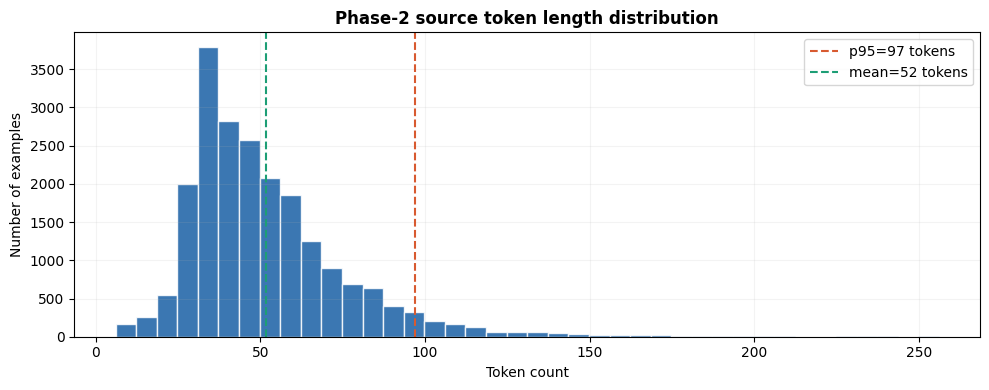

Train: 21224 | Val: 1118


In [21]:
# ========================================================
# P2-2.2: INITIALIZE DEDICATED PHASE 2 TOKENIZER & MAP DATA
# ========================================================
from transformers import NllbTokenizerFast
from pathlib import Path

print("Initializing dedicated Phase 2 tokenizer...")

# 1. Define the path locally using the CKPT_DIR from Section 0.2
p1_final_path = Path(CKPT_DIR) / 'final'

# 2. Inherit basic setup from Phase 1 saved results if available
if p1_final_path.exists():
    print(f"Found Phase 1 final weights at: {p1_final_path}")
    p2_tokenizer = NllbTokenizerFast.from_pretrained(str(p1_final_path))
else:
    p2_tokenizer = NllbTokenizerFast.from_pretrained(MODEL_NAME)
    p2_tokenizer.add_special_tokens({'additional_special_tokens': ['<en2ar>', '<ar2en>']})

# Safely add the masked and structural tokens only for Phase 2
p2_custom_tokens = ['<REF>', '<CITATION>'] + [f"<MATH_{i}>" for i in range(100)]
n_p2_added = p2_tokenizer.add_special_tokens({'additional_special_tokens': p2_custom_tokens})

print(f"Phase 1 Vocab Size: {len(tokenizer)}")
print(f"Phase 2 Vocab Size: {len(p2_tokenizer)} (Added: {n_p2_added} tokens)")

# Tokenize Phase 2 dataset using the new p2_tokenizer
print("Tokenising Phase-2 dataset ...")
p2_tokenized = p2_raw_ds.map(
    make_tokenize_fn(p2_tokenizer, P2_TRAIN_CONFIG['max_source_length'], P2_TRAIN_CONFIG['max_target_length']),
    batched=True,
)
p2_tokenized = p2_raw_ds.map(
    make_tokenize_fn(tokenizer,
                     P2_TRAIN_CONFIG['max_source_length'],
                     P2_TRAIN_CONFIG['max_target_length']),
    batched=True, batch_size=500,
    remove_columns=['source', 'target'],
    desc='Tokenising P2',
    num_proc=1,
)
row = p2_tokenized['train'][0]
print(f"\nTokenised row shape:")
print(f"  input_ids      : ({len(row['input_ids'])},)")
print(f"  attention_mask : ({len(row['attention_mask'])},)")
print(f"  labels         : ({len(row['labels'])},)   first 10: {row['labels'][:10]}")

tok_lens = [len(r['input_ids']) for r in p2_tokenized['train']]
trunc = sum(1 for l in tok_lens if l == P2_TRAIN_CONFIG['max_source_length'])
print(f"\nToken length distribution:")
print(f"  avg={np.mean(tok_lens):.1f}  p95={np.percentile(tok_lens,95):.0f}  max={max(tok_lens)}")
print(f"  Truncated at 256: {trunc} ({100*trunc/len(tok_lens):.1f}%)  — ideally <2%")

# Distribution histogram
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(tok_lens, bins=40, color='#185FA5', edgecolor='white', alpha=0.85)
ax.axvline(np.percentile(tok_lens, 95), color='#D85A30', linestyle='--', linewidth=1.5,
           label=f'p95={np.percentile(tok_lens,95):.0f} tokens')
ax.axvline(np.mean(tok_lens), color='#1D9E75', linestyle='--', linewidth=1.5,
           label=f'mean={np.mean(tok_lens):.0f} tokens')
ax.set_title('Phase-2 source token length distribution', fontweight='bold')
ax.set_xlabel('Token count'); ax.set_ylabel('Number of examples')
ax.legend(); ax.grid(alpha=0.15)
plt.tight_layout(); plt.show()
print(f"Train: {len(p2_tokenized['train'])} | Val: {len(p2_tokenized['validation'])}")


## Phase 2 — Section P2-3 · Model setup — load Phase-1 best, attach fresh Phase-2 LoRA

In [22]:
# P2-3.1  Load Phase-1 final model and attach a NEW Phase-2 LoRA adapter
# Strategy: we load the Phase-1 merged weights (not the base NLLB),
# then attach a fresh LoRA adapter with the smaller Phase-2 rank.
# This preserves everything P1 learned while allowing targeted updates.

from peft import LoraConfig, TaskType, get_peft_model, PeftModel
from transformers import AutoModelForSeq2SeqLM, NllbTokenizerFast

P1_FINAL_DIR = Path(CKPT_DIR) / 'final'
P1_LAST_CKPT, _ = find_latest_checkpoint(CKPT_DIR)

if P1_FINAL_DIR.exists():
    print(f"Loading Phase-1 merged model from: {P1_FINAL_DIR}")
    p2_base = AutoModelForSeq2SeqLM.from_pretrained(
        str(P1_FINAL_DIR),
        torch_dtype=torch.float16 if device == 'cuda' else torch.float32,
    )
    p2_base.resize_token_embeddings(len(p2_tokenizer))
elif P1_LAST_CKPT:
    print(f"Phase-1 final not found. Using latest checkpoint: {P1_LAST_CKPT}")
    p2_base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16)
    p2_base.resize_token_embeddings(len(p2_tokenizer))
    p2_base = PeftModel.from_pretrained(p2_base, P1_LAST_CKPT)
    p2_base = p2_base.merge_and_unload()
else:
    print("WARNING: No Phase-1 checkpoint found. Starting from base NLLB.")
    print("Run Phase 1 training (Section 5) first for best results.")
    p2_base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16)
    p2_base.resize_token_embeddings(len(tokenizer))

# Attach fresh Phase-2 LoRA adapter
p2_lora_cfg = LoraConfig(
    r               = P2_LORA_CONFIG['r'],
    lora_alpha      = P2_LORA_CONFIG['lora_alpha'],
    target_modules  = P2_LORA_CONFIG['target_modules'],
    lora_dropout    = P2_LORA_CONFIG['lora_dropout'],
    bias            = P2_LORA_CONFIG['bias'],
    task_type       = TaskType.SEQ_2_SEQ_LM,
)
p2_model = get_peft_model(p2_base, p2_lora_cfg)
for param in p2_model.parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)
p2_model.enable_input_require_grads()
p2_model.config.use_cache = False
if hasattr(p2_model.base_model, 'prepare_decoder_input_ids_from_labels'):
    p2_model.prepare_decoder_input_ids_from_labels = \
        p2_model.base_model.prepare_decoder_input_ids_from_labels

p2_model.to(device)
p2_model.print_trainable_parameters()

total   = sum(p.numel() for p in p2_model.parameters())
trained = sum(p.numel() for p in p2_model.parameters() if p.requires_grad)
print(f"\n  Total     : {total/1e6:.1f}M")
print(f"  Trainable : {trained/1e6:.2f}M  ({100*trained/total:.3f}%  — Phase-2 LoRA adapters)")
print(f"  Frozen    : {(total-trained)/1e6:.1f}M  — Phase-1 weights, preserved")


Loading Phase-1 merged model from: /content/drive/MyDrive/mathtrans/checkpoints/final
trainable params: 4,718,592 || all params: 1,375,461,376 || trainable%: 0.3430552164047099

  Total     : 1375.5M
  Trainable : 4.72M  (0.343%  — Phase-2 LoRA adapters)
  Frozen    : 1370.7M  — Phase-1 weights, preserved


## Phase 2 — Section P2-4 · Training

**Re-run this single cell after any Colab disconnect** — auto-resumes from the latest Phase-2 checkpoint.

The masked-math objective forces the model to rely on *context* rather than verbatim LaTeX copying.  
After training, a sentence like *"The [MATH] of a non-negative [MATH] is the [MATH] of integrals"*  
must be translated correctly — proving the model understands mathematical terminology, not just notation.


In [ ]:
# P2-4.1  Phase-2 training loop — re-run after any disconnect
import torch, numpy._core.multiarray
torch.serialization.add_safe_globals([
    numpy._core.multiarray._reconstruct,
    np.ndarray, np.dtype,
])
try:
    torch.serialization.add_safe_globals([np.dtypes.UInt32DType])
except AttributeError:
    pass  # older numpy

from transformers import (Seq2SeqTrainer, Seq2SeqTrainingArguments,
                           DataCollatorForSeq2Seq, EarlyStoppingCallback)

cfg = P2_TRAIN_CONFIG
eff_batch = cfg['per_device_train_batch_size'] * cfg['gradient_accumulation_steps']
n_train   = len(p2_tokenized['train'])
steps_epoch  = math.ceil(n_train / eff_batch)
total_steps  = steps_epoch * cfg['num_train_epochs']
last_p2_ckpt, steps_done = find_latest_checkpoint(P2_CKPT_DIR)

print(f"Checkpoint      : {last_p2_ckpt or 'none — fresh Phase-2 start'}")
print(f"Steps done      : {steps_done} / {total_steps}")
print(f"Steps/epoch     : {steps_epoch}")
print(f"Eff. batch size : {eff_batch}  (vs {TRAIN_CONFIG['per_device_train_batch_size']*TRAIN_CONFIG['gradient_accumulation_steps']} in Phase 1)")
print(f"Learning rate   : {cfg['learning_rate']}  (vs {TRAIN_CONFIG['learning_rate']} in Phase 1)")
print(f"Est. remaining  : ~{max(0, total_steps-steps_done)*3.5/3600:.1f} h on T4")

p2_training_args = Seq2SeqTrainingArguments(
    output_dir                  = P2_CKPT_DIR,
    per_device_train_batch_size = cfg['per_device_train_batch_size'],
    per_device_eval_batch_size  = cfg['per_device_eval_batch_size'],
    gradient_accumulation_steps = cfg['gradient_accumulation_steps'],
    learning_rate               = cfg['learning_rate'],
    lr_scheduler_type           = cfg['lr_scheduler_type'],
    warmup_ratio                = cfg['warmup_ratio'],
    num_train_epochs            = cfg['num_train_epochs'],
    weight_decay                = cfg['weight_decay'],
    label_smoothing_factor      = cfg['label_smoothing_factor'],
    fp16                        = (device == 'cuda'),
    save_strategy               = 'steps', save_steps=cfg['save_steps'],
    save_total_limit            = cfg['save_total_limit'],
    evaluation_strategy         = 'steps', eval_steps=cfg['eval_steps'],
    load_best_model_at_end      = True,
    metric_for_best_model       = 'chrf',
    greater_is_better           = True,
    predict_with_generate       = True,
    generation_num_beams        = cfg['eval_num_beams'],
    generation_max_length       = cfg['eval_generation_max_length'],
    gradient_checkpointing      = False,
    dataloader_pin_memory       = (device == 'cuda'),
    logging_steps               = cfg['logging_steps'],
    report_to                   = 'none',
    seed                        = cfg['seed'],
)

p2_trainer = Seq2SeqTrainer(
    model           = p2_model,
    args            = p2_training_args,
    train_dataset   = p2_tokenized['train'],
    eval_dataset    = p2_tokenized['validation'],
    tokenizer       = p2_tokenizer,
    data_collator   = DataCollatorForSeq2Seq(
        p2_tokenizer, model=p2_model, padding='longest',
        pad_to_multiple_of=8, label_pad_token_id=-100,
    ),
    compute_metrics = build_compute_metrics(p2_tokenizer),
    callbacks       = [
        EarlyStoppingCallback(early_stopping_patience=3),  # +1 patience vs P1
        ClearCacheBeforeEval(),
        SaveCurvesCallback(P2_CURVES_PATH),
    ],
)

p2_trainer.train(resume_from_checkpoint=last_p2_ckpt)

# ── post-training: save hashes, merge LoRA, final eval ──
save_new_hashes(P2_SEEN_PATH, p2_new_hashes)
with open(P2_CURVES_PATH, 'w') as f:
    json.dump(p2_trainer.state.log_history, f, indent=2)
print(f"Curves saved → {P2_CURVES_PATH}")

p2_model.config.use_cache = True
p2_final_dir = Path(P2_CKPT_DIR) / 'final'
print(f"Merging Phase-2 LoRA → {p2_final_dir}")
p2_model.merge_and_unload().save_pretrained(str(p2_final_dir))
tokenizer.save_pretrained(str(p2_final_dir))
p2_model = p2_model.half()

torch.cuda.empty_cache()
m2 = p2_trainer.evaluate(
    max_length=cfg['final_generation_max_length'],
    num_beams=cfg['final_num_beams'],
)
print(f"Phase-2 final chrF++ : {m2.get('eval_chrf','?')}")
print(f"Phase-2 final BLEU   : {m2.get('eval_bleu','?')}")


Checkpoint      : none — fresh Phase-2 start
Steps done      : 0 / 2656
Steps/epoch     : 664
Eff. batch size : 32  (vs 64 in Phase 1)
Learning rate   : 8e-05  (vs 0.0003 in Phase 1)
Est. remaining  : ~2.6 h on T4


Step,Training Loss,Validation Loss


## Phase 2 — Section P2-5 · Checkpoint explorer

In [ ]:
# P2-5.1  Test sentences (same as Phase 1 for comparability)
# We reuse the TEST_TRAIN / TEST_EVAL / REF_ variables from Section 6.1
# so Phase-2 results can be directly compared.
print("Phase-2 test sentences (reusing Phase-1 refs for direct comparison):")
print(f"  Train ex: {TEST_TRAIN[:80]}...")
print(f"  Eval  ex: {TEST_EVAL[:80]}...")

# Also test a sentence where math was masked — hardest case
TEST_MASKED = 'Let [MATH] be a non-negative measurable function. Then [MATH] if and only if [MATH] belongs to [MATH].'
print(f"\n  Masked ex: {TEST_MASKED}")


In [ ]:
# P2-5.2  Sweep all Phase-2 checkpoints (same pattern as Section 6.4)
from peft import PeftModel
import random
from tqdm.auto import tqdm

p2_sweep_results = []
p2_all_ckpts     = find_checkpoints(P2_CKPT_DIR)
p2_final_path    = Path(P2_CKPT_DIR) / 'final'
if p2_final_path.exists():
    p2_all_ckpts.append(p2_final_path)

if not p2_all_ckpts:
    print("No Phase-2 checkpoints yet. Run P2-4 first.")
else:
    # Use the SAME 100 eval samples drawn in Section 6.1 for fair comparison
    print(f"Sweeping {len(p2_all_ckpts)} Phase-2 models on {len(eval_samples)} eval examples ...")

    p2_base_for_lora = None  # re-used across checkpoints to save download time

    for ckpt in p2_all_ckpts:
        ckpt_name = ckpt.name if hasattr(ckpt, 'name') else ckpt.parts[-1]
        print(f"\nLoading {ckpt_name} ...")

        if ckpt_name == 'final':
            ft_tok  = NllbTokenizerFast.from_pretrained(str(ckpt))
            ft_mdl  = AutoModelForSeq2SeqLM.from_pretrained(
                str(ckpt), torch_dtype=torch.float16).to(device)
        else:
            if p2_base_for_lora is None:
                # We need the P1-merged weights as the base for P2 LoRA checkpoints
                p1_final = Path(CKPT_DIR) / 'final'
                base_src = str(p1_final) if p1_final.exists() else MODEL_NAME
                p2_base_for_lora = AutoModelForSeq2SeqLM.from_pretrained(
                    base_src, torch_dtype=torch.float16)
            ft_tok = NllbTokenizerFast.from_pretrained(str(ckpt))
            _b = p2_base_for_lora.__class__.from_pretrained(
                    str(Path(CKPT_DIR) / 'final') if (Path(CKPT_DIR)/'final').exists() else MODEL_NAME,
                    torch_dtype=torch.float16)
            _b.resize_token_embeddings(len(ft_tok))
            ft_mdl = PeftModel.from_pretrained(_b, str(ckpt)).to(device)

        ft_mdl.eval()
        c, b = evaluate_100_samples(eval_samples, ft_tok, ft_mdl)
        print(f"  chrF++: {c:.2f}  BLEU: {b:.2f}")
        p2_sweep_results.append({
            'name':  ckpt_name.replace('checkpoint-', 'p2ckpt-'),
            'chrf':  c,
            'bleu':  b,
        })
        del ft_mdl
        if ckpt_name != 'final' and '_b' in dir(): del _b
        torch.cuda.empty_cache()

    print("\nPhase-2 sweep complete.")
    for r in p2_sweep_results:
        print(f"  {r['name']:<20}  chrF++={r['chrf']:.2f}  BLEU={r['bleu']:.2f}")


## Phase 2 — Section P2-6 · Phase-2 metrics plots

In [ ]:
# P2-6.1  Load Phase-2 training curves
if not os.path.exists(P2_CURVES_PATH):
    print(f"No Phase-2 curves at {P2_CURVES_PATH} — run P2-4 first.")
    p2_history = []
else:
    with open(P2_CURVES_PATH) as f:
        p2_history = json.load(f)
    print(f"Loaded {len(p2_history)} log entries from Phase-2 training.")
    print(f"Keys in last entry: {list(p2_history[-1].keys()) if p2_history else 'empty'}")


In [ ]:
# P2-6.2  Phase-2 full training curves — loss / chrF++ / BLEU / LR
if not p2_history:
    print("No Phase-2 history yet.")
else:
    cfg2 = P2_TRAIN_CONFIG
    train_logs = [h for h in p2_history if 'loss' in h and 'eval_loss' not in h]
    eval_logs  = [h for h in p2_history if 'eval_chrf' in h]

    st = [h['step']  for h in train_logs]
    lt = [h['loss']  for h in train_logs]
    lr = [h.get('learning_rate', 0) for h in train_logs]
    se = [h['step']       for h in eval_logs]
    ce = [h['eval_chrf']  for h in eval_logs]
    be = [h['eval_bleu']  for h in eval_logs]
    el = [h.get('eval_loss') for h in eval_logs]

    spe2 = math.ceil(len(p2_tokenized['train']) /
                     (cfg2['per_device_train_batch_size'] * cfg2['gradient_accumulation_steps']))
    epoch_marks2 = [spe2 * (i + 1) for i in range(cfg2['num_train_epochs'])]

    BLUE='#185FA5'; GREEN='#1D9E75'; ORANGE='#D85A30'; PURPLE='#534AB7'; TARGET='#BA7517'

    def epoch_lines2(ax):
        ylim = ax.get_ylim()
        for es in epoch_marks2:
            ax.axvline(x=es, color='#aaa', linestyle=':', linewidth=0.8, alpha=0.7)
            ax.text(es + max(st)/150 if st else 1, ylim[0]+(ylim[1]-ylim[0])*0.03,
                    'ep', fontsize=8, color='#aaa')

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('MathTrans Phase 2 — Training metrics (masked-math objective)',
                 fontsize=14, fontweight='bold')

    # Loss
    ax = axes[0][0]
    if st: ax.plot(st, lt, color=BLUE, linewidth=1.5, label='train loss')
    valid_el = [(s, l) for s, l in zip(se, el) if l is not None]
    if valid_el:
        ax.plot([x[0] for x in valid_el], [x[1] for x in valid_el],
                'o--', color=ORANGE, markersize=4, linewidth=1, label='eval loss')
    epoch_lines2(ax)
    ax.set_title('Loss (P2)'); ax.set_xlabel('Step'); ax.set_ylabel('Cross-entropy')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    # chrF++
    ax = axes[0][1]
    if se:
        ax.plot(se, ce, color=GREEN, linewidth=2, marker='o', markersize=4, label='val chrF++ P2')
        ax.axhline(y=45, color=TARGET, linestyle='--', linewidth=1.2, label='target 45', alpha=0.8)
        if ce:
            bi = ce.index(max(ce))
            ax.scatter([se[bi]], [ce[bi]], color=GREEN, s=80, zorder=5,
                       label=f'best={max(ce):.1f} @{se[bi]}')
    if 'base_eval_chrf' in dir():
        ax.axhline(y=base_eval_chrf, color='#888', linestyle=':', linewidth=1,
                   label=f'base NLLB={base_eval_chrf:.1f}', alpha=0.8)
    epoch_lines2(ax)
    ax.set_title('Validation chrF++ (P2)'); ax.set_xlabel('Step'); ax.set_ylabel('chrF++')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # BLEU
    ax = axes[1][0]
    if se:
        ax.plot(se, be, color=ORANGE, linewidth=2, marker='o', markersize=4, label='val BLEU P2')
        ax.axhline(y=25, color=TARGET, linestyle='--', linewidth=1.2, label='target 25', alpha=0.8)
    epoch_lines2(ax)
    ax.set_title('Validation BLEU (P2)'); ax.set_xlabel('Step'); ax.set_ylabel('BLEU')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # Learning rate
    ax = axes[1][1]
    if st: ax.plot(st, lr, color=PURPLE, linewidth=1.5, label='LR (P2)')
    epoch_lines2(ax)
    ax.set_title('Learning rate P2 (cosine warmup)'); ax.set_xlabel('Step')
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2e'))
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    plt.tight_layout()
    out = f'{P2_CKPT_DIR}/training_curves_p2_full.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")


In [ ]:
# P2-6.3  Phase-2 checkpoint bar chart (chrF++ & BLEU)
if not p2_sweep_results:
    print("Run P2-5.2 (sweep) first.")
else:
    names2       = ['Base'] + [r['name'] for r in p2_sweep_results]
    chrf_scores2 = [base_eval_chrf] + [r['chrf'] for r in p2_sweep_results]
    bleu_scores2 = [base_eval_bleu] + [r['bleu'] for r in p2_sweep_results]

    x = np.arange(len(names2))
    width = 0.35

    fig, ax = plt.subplots(figsize=(14, 7), facecolor='#f8f9fa')
    r1 = ax.bar(x - width/2, chrf_scores2, width, label='chrF++', color='#28a745', edgecolor='black')
    r2 = ax.bar(x + width/2, bleu_scores2, width, label='BLEU',   color='#007bff', edgecolor='black')
    ax.set_ylabel('Score (0–100)', fontsize=12, fontweight='bold')
    ax.set_title('Phase-2 Model Evolution — 100 Random Examples', fontsize=14, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(names2, rotation=45, ha='right', fontsize=10)
    ax.legend(fontsize=12); ax.grid(axis='y', linestyle='--', alpha=0.7)

    for rects in [r1, r2]:
        for rect in rects:
            h = rect.get_height()
            ax.annotate(f'{h:.1f}',
                        xy=(rect.get_x() + rect.get_width()/2, h),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    out = f'{P2_CKPT_DIR}/p2_checkpoint_comparison.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")


## Phase 2 — Section P2-7 · Phase 1 vs Phase 2 Comparison

This section compares the **best checkpoint from each phase** on the same 100 evaluation examples.

| Axis | Phase 1 | Phase 2 |
|---|---|---|
| Dataset | ~78 K full-text pairs | 20 K math-masked pairs |
| Objective | EN↔AR translation | Translation without copying LaTeX |
| LoRA rank | 16 | 8 |
| Eff. batch | 64 | 32 |
| LR | 3e-4 | 8e-5 |
| Epochs | 3 | 4 |

**What to expect:**  
- Phase 2 *chrF++* may be slightly lower on unmasked test sentences (it was trained on masked inputs).  
- Phase 2 should be *more robust* on sentences where LaTeX is absent or replaced — it can't rely on verbatim symbol copying.  
- Loss curves will be smoother (lower LR, smaller batches, more regularisation).


In [ ]:
# P2-7.1  Side-by-side training curves — Phase 1 vs Phase 2
# Requires: history (P1) and p2_history (P2) both loaded

if not history or not p2_history:
    print("Load both Phase-1 (Section 7.1) and Phase-2 (P2-6.1) histories first.")
else:
    def extract_curves(hist):
        train = [h for h in hist if 'loss' in h and 'eval_loss' not in h]
        evalu = [h for h in hist if 'eval_chrf' in h]
        return (
            [h['step'] for h in train], [h['loss'] for h in train],
            [h.get('learning_rate', 0) for h in train],
            [h['step'] for h in evalu], [h['eval_chrf'] for h in evalu],
            [h['eval_bleu'] for h in evalu],
        )

    p1_st, p1_lt, p1_lr, p1_se, p1_ce, p1_be = extract_curves(history)
    p2_st, p2_lt, p2_lr, p2_se, p2_ce, p2_be = extract_curves(p2_history)

    BLUE='#185FA5'; GREEN='#1D9E75'; ORANGE='#D85A30'; PURPLE='#534AB7'
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('Phase 1 vs Phase 2 — Training Comparison', fontsize=15, fontweight='bold')

    # Train loss
    ax = axes[0][0]
    if p1_st: ax.plot(p1_st, p1_lt, color=BLUE,   linewidth=1.5, label='P1 train loss', alpha=0.85)
    if p2_st: ax.plot(p2_st, p2_lt, color=ORANGE, linewidth=1.5, label='P2 train loss', alpha=0.85)
    ax.set_title('Train Loss'); ax.set_xlabel('Step'); ax.set_ylabel('Cross-entropy')
    ax.legend(); ax.grid(alpha=0.15)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    # Eval chrF++
    ax = axes[0][1]
    if p1_se: ax.plot(p1_se, p1_ce, color=BLUE,   linewidth=2, marker='o', markersize=3,
                      label=f'P1 val chrF++ (best={max(p1_ce):.1f})')
    if p2_se: ax.plot(p2_se, p2_ce, color=GREEN,  linewidth=2, marker='s', markersize=3,
                      label=f'P2 val chrF++ (best={max(p2_ce):.1f})')
    ax.set_title('Validation chrF++'); ax.set_xlabel('Step'); ax.set_ylabel('chrF++')
    ax.legend(); ax.grid(alpha=0.15)

    # Eval BLEU
    ax = axes[1][0]
    if p1_se: ax.plot(p1_se, p1_be, color=BLUE,   linewidth=2, marker='o', markersize=3,
                      label=f'P1 val BLEU (best={max(p1_be):.1f})')
    if p2_se: ax.plot(p2_se, p2_be, color=ORANGE, linewidth=2, marker='s', markersize=3,
                      label=f'P2 val BLEU (best={max(p2_be):.1f})')
    ax.set_title('Validation BLEU'); ax.set_xlabel('Step'); ax.set_ylabel('BLEU')
    ax.legend(); ax.grid(alpha=0.15)

    # Learning rate
    ax = axes[1][1]
    if p1_st: ax.plot(p1_st, p1_lr, color=BLUE,   linewidth=1.5, label='P1 LR', alpha=0.85)
    if p2_st: ax.plot(p2_st, p2_lr, color=PURPLE, linewidth=1.5, label='P2 LR', alpha=0.85)
    ax.set_title('Learning Rate'); ax.set_xlabel('Step')
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2e'))
    ax.legend(); ax.grid(alpha=0.15)

    plt.tight_layout()
    out = f'{DRIVE_ROOT}/p1_vs_p2_training_curves.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")


In [ ]:
# P2-7.2  Best checkpoint score comparison: Base vs P1 final vs P2 final
# Requires sweep_results (P1) and p2_sweep_results (P2)

has_p1 = 'sweep_results' in dir() and sweep_results
has_p2 = 'p2_sweep_results' in dir() and p2_sweep_results
has_base = 'base_eval_chrf' in dir()

if not has_base:
    print("Run Section 6.1 (base model baseline) first.")
elif not has_p1 and not has_p2:
    print("Run at least one sweep (Section 6.4 for P1 or P2-5.2 for P2) first.")
else:
    def best_score(results, key):
        return max(r[key] for r in results) if results else None

    p1_best_chrf = best_score(sweep_results, 'chrf') if has_p1 else None
    p1_best_bleu = best_score(sweep_results, 'bleu') if has_p1 else None
    p2_best_chrf = best_score(p2_sweep_results, 'chrf') if has_p2 else None
    p2_best_bleu = best_score(p2_sweep_results, 'bleu') if has_p2 else None

    # ── Grouped bar chart ──
    labels   = ['Base NLLB']
    chrfs    = [base_eval_chrf]
    bleus    = [base_eval_bleu]
    colors_c = ['#888888']
    colors_b = ['#aaaaaa']

    if p1_best_chrf is not None:
        labels.append('Phase 1\n(translation)'); chrfs.append(p1_best_chrf)
        bleus.append(p1_best_bleu);              colors_c.append('#185FA5'); colors_b.append('#185FA5')
    if p2_best_chrf is not None:
        labels.append('Phase 2\n(masked-math)'); chrfs.append(p2_best_chrf)
        bleus.append(p2_best_bleu);              colors_c.append('#1D9E75'); colors_b.append('#1D9E75')

    x     = np.arange(len(labels))
    width = 0.38

    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    fig.suptitle('Phase 1 vs Phase 2 — Best Checkpoint Comparison\n(100 eval examples)',
                 fontsize=14, fontweight='bold')

    for ax, scores, metric, ylabel in [
        (axes[0], chrfs, 'chrF++', 'chrF++ (higher = better)'),
        (axes[1], bleus, 'BLEU',   'BLEU (higher = better)'),
    ]:
        clrs = colors_c if metric == 'chrF++' else colors_b
        bars = ax.bar(x, scores, width=0.55, color=clrs, edgecolor='white', linewidth=0.8, alpha=0.9)
        ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=11)
        ax.set_ylabel(ylabel, fontsize=11); ax.set_title(metric, fontsize=12, fontweight='bold')
        ax.set_ylim(0, max(scores) * 1.18)
        ax.grid(axis='y', linestyle='--', alpha=0.5)
        for bar, val in zip(bars, scores):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(scores)*0.01,
                    f'{val:.1f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

        # Delta arrows
        base_val = scores[0]
        for i in range(1, len(scores)):
            delta = scores[i] - base_val
            sign  = '+' if delta >= 0 else ''
            ax.text(i, scores[i]/2, f'{sign}{delta:.1f}',
                    ha='center', va='center', fontsize=10,
                    color='white', fontweight='bold')

    plt.tight_layout()
    out = f'{DRIVE_ROOT}/p1_vs_p2_best_comparison.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {out}")

    # ── Text summary ──
    print("\n" + "="*55)
    print("SUMMARY TABLE")
    print("="*55)
    print(f"  {'Model':<22}  {'chrF++':<8}  {'BLEU':<8}  {'ΔchrF++':<8}")
    print(f"  {'-'*50}")
    base_c = base_eval_chrf
    for name, c, b in zip(labels, chrfs, bleus):
        delta = f'{c-base_c:+.1f}' if name != 'Base NLLB' else '—'
        print(f"  {name.replace(chr(10),' '):<22}  {c:<8.2f}  {b:<8.2f}  {delta}")
    print("="*55)


In [ ]:
# P2-7.3  Qualitative comparison — translate the same 3 sentences with both models
from peft import PeftModel as PM

p1_final_dir = Path(CKPT_DIR)    / 'final'
p2_final_dir = Path(P2_CKPT_DIR) / 'final'

TEST_SENTENCES = [
    ('en', 'ar',
     'The Lebesgue integral of a non-negative measurable function is defined as the supremum of simple functions.',
     'تكامل لوبيغ لدالة قابلة للقياس غير سالبة هو الحد الأعلى لتكاملات الدوال البسيطة.'),
    ('en', 'ar',
     'Let $f$ be a continuously differentiable function on $[a,b]$. If $f\'(x) > 0$ for all $x$, then $f$ is strictly increasing.',
     'لتكن $f$ دالة قابلة للاشتقاق بشكل مستمر. إذا كان $f\'(x) > 0$، فإن $f$ متزايدة تمامًا.'),
    ('en', 'ar',
     'The Cauchy-Schwarz inequality states that the inner product of two vectors satisfies certain bounds.',
     'تنص متراجحة كوشي-شوارتز على أن الجداء الداخلي لمتجهين يخضع لقيود معينة.'),
]

def load_final_model(final_dir):
    if not Path(final_dir).exists():
        return None, None
    tok = NllbTokenizerFast.from_pretrained(str(final_dir))
    mdl = AutoModelForSeq2SeqLM.from_pretrained(
        str(final_dir), torch_dtype=torch.float16 if device=='cuda' else torch.float32
    ).to(device)
    mdl.eval()
    return tok, mdl

print("Loading Phase-1 final model ...")
p1_tok, p1_mdl = load_final_model(p1_final_dir)
print("Loading Phase-2 final model ...")
p2_tok, p2_mdl = load_final_model(p2_final_dir)

if p1_mdl is None and p2_mdl is None:
    print("Neither final model found. Run P1 Section 5 and P2-4 training first.")
else:
    chrf_m_q = hf_evaluate.load('chrf')

    print("\n" + "="*70)
    print("QUALITATIVE COMPARISON — Phase 1 vs Phase 2")
    print("="*70)

    for i, (src_lang, tgt_lang, src, ref) in enumerate(TEST_SENTENCES):
        print(f"\n[{i+1}] Source: {src[:100]}")
        print(f"    Ref   : {ref[:100]}")

        # mask the source for the masked-test version
        masked_src, n = mask_math(src)
        if n > 0:
            print(f"    Masked: {masked_src[:100]}  (P2 input)")

        for label, tok, mdl in [('Phase 1', p1_tok, p1_mdl), ('Phase 2', p2_tok, p2_mdl)]:
            if mdl is None:
                print(f"    {label:<8}: [model not available]")
                continue
            pred = translate(src, tok, mdl, src=src_lang, tgt=tgt_lang, beams=4)
            c    = chrf_m_q.compute(predictions=[pred], references=[ref], word_order=2)['score']
            print(f"    {label:<8}: {pred[:100]}   [chrF++={c:.1f}]")

    if p1_mdl: del p1_mdl
    if p2_mdl: del p2_mdl
    torch.cuda.empty_cache()
